# RQ1第三步：Multi-output Ridge trajectory model

这份notebook实现proposal中的learned forecasting model。它使用每个case过去24小时的轨迹和速度，一次预测未来72小时的完整轨迹。

模型只使用3,591个training cases拟合参数，并且在training drifters内部进行grouped cross-validation选择正则化强度。Calibration set不参与训练或选择，继续保留给后续conformal prediction；最终结果只在与两个baselines完全相同的757个test cases上报告。

## 1. 模型定义

每个case的输入由以下内容组成：

- forecast origin的纬度和经度，用于提供空间背景；
- 过去24小时相对于origin的东向、北向位移；
- 过去24小时的东西向速度 $v_e$ 和南北向速度 $v_n$。

因此每个case有 $2+24\times4=98$ 个输入特征。输出为未来72小时相对于origin的东向、北向位移，共 $72\times2=144$ 个目标。

Multi-output Ridge同时估计所有未来时刻：

$$\hat Y=XB,$$

$$\hat B=\arg\min_B\left\{\lVert Y-XB\rVert_F^2+\alpha\lVert B\rVert_F^2\right\}.$$

Ridge的正则化参数 $\alpha$ 限制系数过大，适合处理24小时序列中高度相关的输入变量。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到data/processed；请从项目目录或notebooks子目录打开。')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
OUTPUT_DIR = PROJECT_ROOT / 'output' / 'rq1' / 'zh'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EARTH_RADIUS_KM = 6_371.0
HISTORY_HOURS = 24
HORIZON_HOURS = 72
ALPHAS = np.array([0.1, 1.0, 10.0, 100.0, 1_000.0, 10_000.0])
N_FOLDS = 5

plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目目录：', PROJECT_ROOT.resolve())
print('结果目录：', OUTPUT_DIR.resolve())

项目目录： /Users/roger/Documents/data3001-project-main
结果目录： /Users/roger/Documents/data3001-project-main/output/rq1/zh


## 2. 球面位置与局部位移的转换

模型不直接回归绝对经纬度，而是回归相对于forecast origin的东向和北向位移（km）。下面使用球面大圆距离和初始方位角进行转换，并提供逆转换将模型输出恢复为经纬度。

In [2]:
def latlon_to_local_km(origin_lat, origin_lon, latitude, longitude):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    lat1 = np.deg2rad(np.asarray(latitude, dtype=float))
    lon1 = np.deg2rad(np.asarray(longitude, dtype=float))
    dlon = (lon1 - lon0 + np.pi) % (2 * np.pi) - np.pi
    dlat = lat1 - lat0

    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin(dlon / 2) ** 2
    central_angle = 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    bearing = np.arctan2(
        np.sin(dlon) * np.cos(lat1),
        np.cos(lat0) * np.sin(lat1) - np.sin(lat0) * np.cos(lat1) * np.cos(dlon),
    )
    distance_km = EARTH_RADIUS_KM * central_angle
    east_km = distance_km * np.sin(bearing)
    north_km = distance_km * np.cos(bearing)
    return east_km, north_km


def local_km_to_latlon(origin_lat, origin_lon, east_km, north_km):
    lat0 = np.deg2rad(np.asarray(origin_lat, dtype=float))
    lon0 = np.deg2rad(np.asarray(origin_lon, dtype=float))
    east_km = np.asarray(east_km, dtype=float)
    north_km = np.asarray(north_km, dtype=float)
    distance_km = np.hypot(east_km, north_km)
    bearing = np.arctan2(east_km, north_km)
    angular_distance = distance_km / EARTH_RADIUS_KM

    latitude = np.arcsin(
        np.sin(lat0) * np.cos(angular_distance)
        + np.cos(lat0) * np.sin(angular_distance) * np.cos(bearing)
    )
    longitude = lon0 + np.arctan2(
        np.sin(bearing) * np.sin(angular_distance) * np.cos(lat0),
        np.cos(angular_distance) - np.sin(lat0) * np.sin(latitude),
    )
    return np.rad2deg(latitude), (np.rad2deg(longitude) + 180.0) % 360.0 - 180.0


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.deg2rad(np.asarray(lat1, dtype=float))
    lon1 = np.deg2rad(np.asarray(lon1, dtype=float))
    lat2 = np.deg2rad(np.asarray(lat2, dtype=float))
    lon2 = np.deg2rad(np.asarray(lon2, dtype=float))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

## 3. 读取固定cases并构造过去24小时输入

这里不重新抽样或改变partition。每个case从所属连续轨迹段中提取恰好24条历史观测，并转换成相对于origin的位移。所有case按照`forecast_case_id`固定顺序排列。

In [3]:
origins = (
    pd.read_parquet(PROCESSED / 'forecast_origins.parquet')
    .sort_values('forecast_case_id').reset_index(drop=True)
)
observations = pd.read_parquet(
    PROCESSED / 'region_A_observations.parquet',
    columns=['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude', 've', 'vn'],
)
n_cases = len(origins)

history = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'history_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HISTORY_HOURS)].reset_index(drop=True)
history['history_index'] = np.tile(np.arange(HISTORY_HOURS), n_cases)
history['segment_step'] = history['history_start_step'] + history['history_index']
history = history.merge(
    observations,
    on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'history_index']).reset_index(drop=True)

history['relative_east_km'], history['relative_north_km'] = latlon_to_local_km(
    history['origin_latitude'], history['origin_longitude'],
    history['latitude'], history['longitude'],
)

history_values = history[[
    'relative_east_km', 'relative_north_km', 've', 'vn',
]].to_numpy().reshape(n_cases, HISTORY_HOURS, 4)

X = np.column_stack([
    origins['origin_latitude'].to_numpy(),
    origins['origin_longitude'].to_numpy(),
    history_values.reshape(n_cases, -1),
])

history_checks = pd.Series({
    '全部cases数量为5117': n_cases == 5117,
    '每个case恰好24条历史观测': history.groupby('forecast_case_id').size().eq(24).all(),
    '输入矩阵形状为5117×98': X.shape == (5117, 98),
    '输入中没有缺失或无限值': np.isfinite(X).all(),
}, name='是否通过')
display(history_checks.to_frame())
assert history_checks.all()

,是否通过
全部cases数量为5117,True
每个case恰好24条历史观测,True
输入矩阵形状为5117×98,True
输入中没有缺失或无限值,True


## 4. 构造未来72小时训练目标

每个case的真实未来轨迹转换成72组相对于origin的东向、北向位移。最终目标矩阵`Y`的形状为 $5,117\times144$。

In [4]:
targets = origins[[
    'forecast_case_id', 'ID', 'segment_id', 'target_start_step',
    'origin_latitude', 'origin_longitude',
]].loc[origins.index.repeat(HORIZON_HOURS)].reset_index(drop=True)
targets['lead_time_hours'] = np.tile(np.arange(1, HORIZON_HOURS + 1), n_cases)
targets['segment_step'] = targets['target_start_step'] + targets['lead_time_hours'] - 1
targets = targets.merge(
    observations[['ID', 'segment_id', 'segment_step', 'time', 'latitude', 'longitude']],
    on=['ID', 'segment_id', 'segment_step'],
    how='left', validate='many_to_one',
).sort_values(['forecast_case_id', 'lead_time_hours']).reset_index(drop=True)

targets['target_east_km'], targets['target_north_km'] = latlon_to_local_km(
    targets['origin_latitude'], targets['origin_longitude'],
    targets['latitude'], targets['longitude'],
)
target_displacements = targets[['target_east_km', 'target_north_km']].to_numpy()
Y = target_displacements.reshape(n_cases, HORIZON_HOURS * 2)

target_checks = pd.Series({
    '每个case恰好72条未来观测': targets.groupby('forecast_case_id').size().eq(72).all(),
    '目标矩阵形状为5117×144': Y.shape == (5117, 144),
    '目标中没有缺失或无限值': np.isfinite(Y).all(),
}, name='是否通过')
display(target_checks.to_frame())
assert target_checks.all()

,是否通过
每个case恰好72条未来观测,True
目标矩阵形状为5117×144,True
目标中没有缺失或无限值,True


## 5. 只在training drifters内部建立5折交叉验证

同一条drifter的所有cases必须进入同一个fold。为了让每个fold的case数量接近，按照每条training drifter产生的case数量，从多到少分配到当前case数最少的fold。

Calibration和test完全不参与选择 $\alpha$。

In [5]:
train_indices = np.flatnonzero(origins['partition'].eq('training').to_numpy())
calibration_indices = np.flatnonzero(origins['partition'].eq('calibration').to_numpy())
test_indices = np.flatnonzero(origins['partition'].eq('test').to_numpy())

training_group_counts = (
    origins.loc[train_indices].groupby('ID').size().sort_values(ascending=False)
)
fold_drifters = [[] for _ in range(N_FOLDS)]
fold_case_counts = np.zeros(N_FOLDS, dtype=int)
for drifter_id, count in training_group_counts.items():
    fold = int(np.argmin(fold_case_counts))
    fold_drifters[fold].append(drifter_id)
    fold_case_counts[fold] += int(count)

fold_summary = pd.DataFrame({
    'Fold': np.arange(1, N_FOLDS + 1),
    'Training drifters held out': [len(x) for x in fold_drifters],
    'Validation cases': fold_case_counts,
})
display(fold_summary)

assert len(train_indices) == 3591
assert len(calibration_indices) == 769
assert len(test_indices) == 757
assert fold_case_counts.sum() == len(train_indices)

,Fold,Training drifters held out,Validation cases
0,1,63,719
1,2,62,718
2,3,62,718
3,4,62,718
4,5,62,718


## 6. 实现并选择Multi-output Ridge

输入特征的均值和标准差只从每个fold的训练部分计算。输出以training mean为截距。验证指标是在144个未来位移坐标上的RMSE（km）；它只用于选择 $\alpha$，最终地理评价仍使用Haversine separation error。

In [6]:
def fit_ridge(X_train, Y_train, alpha):
    x_mean = X_train.mean(axis=0)
    x_scale = X_train.std(axis=0)
    x_scale[x_scale < 1e-12] = 1.0
    y_mean = Y_train.mean(axis=0)

    X_standard = (X_train - x_mean) / x_scale
    gram = X_standard.T @ X_standard
    coefficients = np.linalg.solve(
        gram + alpha * np.eye(gram.shape[0]),
        X_standard.T @ (Y_train - y_mean),
    )
    return {
        'alpha': float(alpha),
        'x_mean': x_mean,
        'x_scale': x_scale,
        'y_mean': y_mean,
        'coefficients': coefficients,
    }


def predict_ridge(model, X_new):
    X_standard = (X_new - model['x_mean']) / model['x_scale']
    return X_standard @ model['coefficients'] + model['y_mean']


cv_rows = []
for alpha in ALPHAS:
    for fold_number, validation_drifters in enumerate(fold_drifters, start=1):
        is_validation = origins.loc[train_indices, 'ID'].isin(validation_drifters).to_numpy()
        fold_validation_indices = train_indices[is_validation]
        fold_training_indices = train_indices[~is_validation]

        fold_model = fit_ridge(X[fold_training_indices], Y[fold_training_indices], alpha)
        fold_predictions = predict_ridge(fold_model, X[fold_validation_indices])
        displacement_rmse = np.sqrt(np.mean(
            np.square(fold_predictions - Y[fold_validation_indices])
        ))
        cv_rows.append({
            'alpha': alpha,
            'fold': fold_number,
            'validation_cases': len(fold_validation_indices),
            'displacement_rmse_km': displacement_rmse,
        })

cv_folds = pd.DataFrame(cv_rows)
cv_results = (
    cv_folds.groupby('alpha')['displacement_rmse_km']
    .agg(mean_cv_rmse_km='mean', std_cv_rmse_km='std')
    .reset_index()
)
best_alpha = float(cv_results.loc[cv_results['mean_cv_rmse_km'].idxmin(), 'alpha'])
display(cv_results.round(3))
print(f'选择的alpha：{best_alpha:g}')

,alpha,mean_cv_rmse_km,std_cv_rmse_km
0,0.1,28.077,1.279
1,1.0,27.945,1.263
2,10.0,27.791,1.294
3,100.0,27.668,1.386
4,1000.0,27.950,1.514
5,10000.0,28.763,1.676


选择的alpha：100


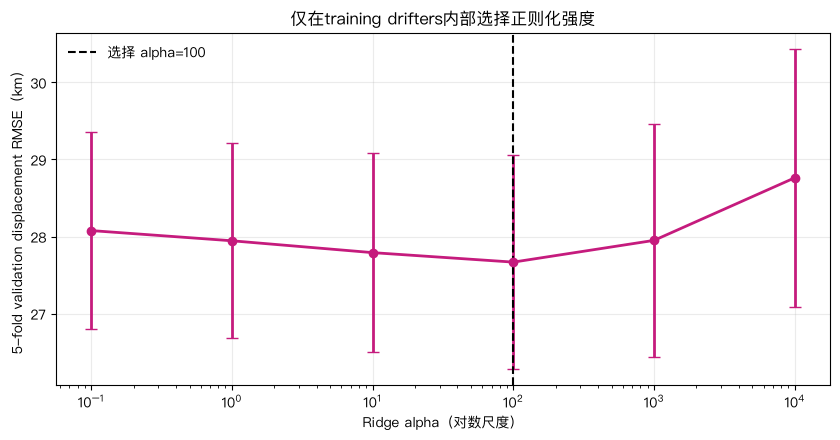

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.errorbar(
    cv_results['alpha'], cv_results['mean_cv_rmse_km'],
    yerr=cv_results['std_cv_rmse_km'], marker='o', capsize=4,
    linewidth=2, color='#c51b7d',
)
ax.axvline(best_alpha, color='black', linestyle='--', linewidth=1.5,
           label=f'选择 alpha={best_alpha:g}')
ax.set_xscale('log')
ax.set(
    xlabel='Ridge alpha（对数尺度）', ylabel='5-fold validation displacement RMSE（km）',
    title='仅在training drifters内部选择正则化强度',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_cross_validation.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. 使用全部training cases拟合最终模型

确定 $\alpha$ 后，用全部3,591个training cases重新拟合一次。模型随后冻结，并一次性预测757个test cases。Calibration cases仍未使用。

In [8]:
final_model = fit_ridge(X[train_indices], Y[train_indices], best_alpha)
test_predictions = predict_ridge(final_model, X[test_indices]).reshape(
    len(test_indices), HORIZON_HOURS, 2
)

test_origins = origins.loc[test_indices].reset_index(drop=True)
origin_latitudes = np.repeat(test_origins['origin_latitude'].to_numpy(), HORIZON_HOURS)
origin_longitudes = np.repeat(test_origins['origin_longitude'].to_numpy(), HORIZON_HOURS)
predicted_latitude, predicted_longitude = local_km_to_latlon(
    origin_latitudes,
    origin_longitudes,
    test_predictions[:, :, 0].reshape(-1),
    test_predictions[:, :, 1].reshape(-1),
)

test_target_mask = targets['forecast_case_id'].isin(test_origins['forecast_case_id'])
test_targets = (
    targets.loc[test_target_mask]
    .sort_values(['forecast_case_id', 'lead_time_hours'])
    .reset_index(drop=True)
)

evaluation = pd.DataFrame({
    'forecast_case_id': np.repeat(test_origins['forecast_case_id'].to_numpy(), HORIZON_HOURS),
    'ID': np.repeat(test_origins['ID'].to_numpy(), HORIZON_HOURS),
    'lead_time_hours': np.tile(np.arange(1, HORIZON_HOURS + 1), len(test_origins)),
    'origin_latitude': origin_latitudes,
    'origin_longitude': origin_longitudes,
    'predicted_east_km': test_predictions[:, :, 0].reshape(-1),
    'predicted_north_km': test_predictions[:, :, 1].reshape(-1),
    'pred_latitude': predicted_latitude,
    'pred_longitude': predicted_longitude,
    'true_latitude': test_targets['latitude'].to_numpy(),
    'true_longitude': test_targets['longitude'].to_numpy(),
})
evaluation['separation_error_km'] = haversine_km(
    evaluation['pred_latitude'], evaluation['pred_longitude'],
    evaluation['true_latitude'], evaluation['true_longitude'],
)

checks = pd.Series({
    '只评价757个test cases': evaluation['forecast_case_id'].nunique() == 757,
    '每个test case恰好72个lead times': evaluation.groupby('forecast_case_id').size().eq(72).all(),
    '全部误差均为有限数值': np.isfinite(evaluation['separation_error_km']).all(),
    'Calibration cases仍未用于拟合': len(calibration_indices) == 769,
}, name='是否通过')
display(checks.to_frame())
assert checks.all()

,是否通过
只评价757个test cases,True
每个test case恰好72个lead times,True
全部误差均为有限数值,True
Calibration cases仍未用于拟合,True


## 8. 测试集误差随lead time增长

与两个baselines完全相同，报告每个lead time的median、mean、25%与75%分位数以及RMSE。

,lead_time_hours,n,median_error_km,mean_error_km,q25_error_km,q75_error_km,rmse_km
0,1,757,0.18,0.29,0.11,0.33,0.49
5,6,757,2.52,2.99,1.45,3.72,3.82
11,12,757,5.70,6.99,3.33,8.77,8.92
23,24,757,12.32,15.03,7.15,19.63,18.97
47,48,757,28.27,34.65,17.21,45.69,42.59
71,72,757,44.75,54.23,27.28,70.16,65.91


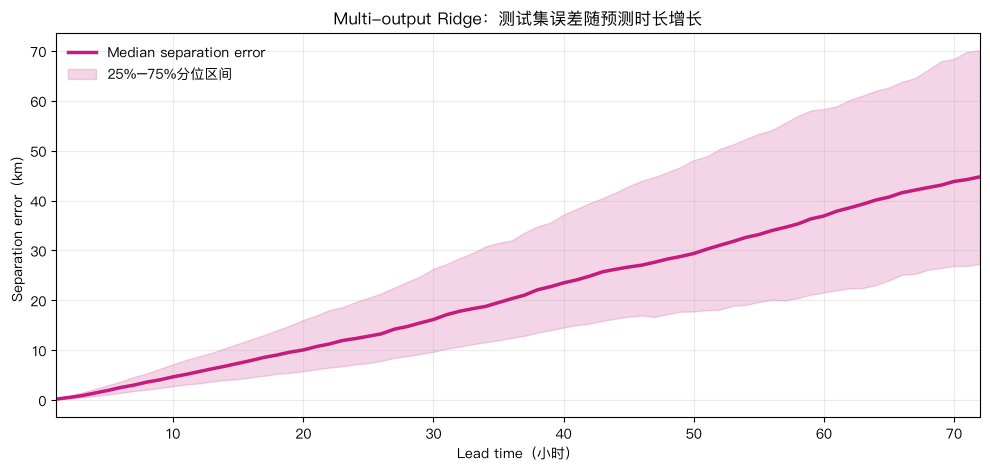

In [9]:
lead_metrics = (
    evaluation.groupby('lead_time_hours')['separation_error_km']
    .agg(
        n='size',
        median_error_km='median',
        mean_error_km='mean',
        q25_error_km=lambda x: x.quantile(0.25),
        q75_error_km=lambda x: x.quantile(0.75),
        rmse_km=lambda x: np.sqrt(np.mean(np.square(x))),
    )
    .reset_index()
)
display(lead_metrics[lead_metrics['lead_time_hours'].isin([1, 6, 12, 24, 48, 72])].round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = lead_metrics['lead_time_hours'].to_numpy()
median = lead_metrics['median_error_km'].to_numpy()
q25 = lead_metrics['q25_error_km'].to_numpy()
q75 = lead_metrics['q75_error_km'].to_numpy()
ax.plot(x, median, color='#c51b7d', linewidth=2.5, label='Median separation error')
ax.fill_between(x, q25, q75, color='#c51b7d', alpha=0.18, label='25%–75%分位区间')
ax.set(
    xlabel='Lead time（小时）', ylabel='Separation error（km）',
    title='Multi-output Ridge：测试集误差随预测时长增长',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_error_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. 与两个baselines公平比较

三种方法使用相同test cases、相同lead times和相同Haversine函数。Forecast skill定义为：

$$\mathrm{Skill}=1-\frac{\mathrm{RMSE}_{\mathrm{Ridge}}}{\mathrm{RMSE}_{\mathrm{baseline}}}.$$

Skill大于0表示Ridge优于对应baseline。表格同时直接显示RMSE差值，避免只并排展示数值。

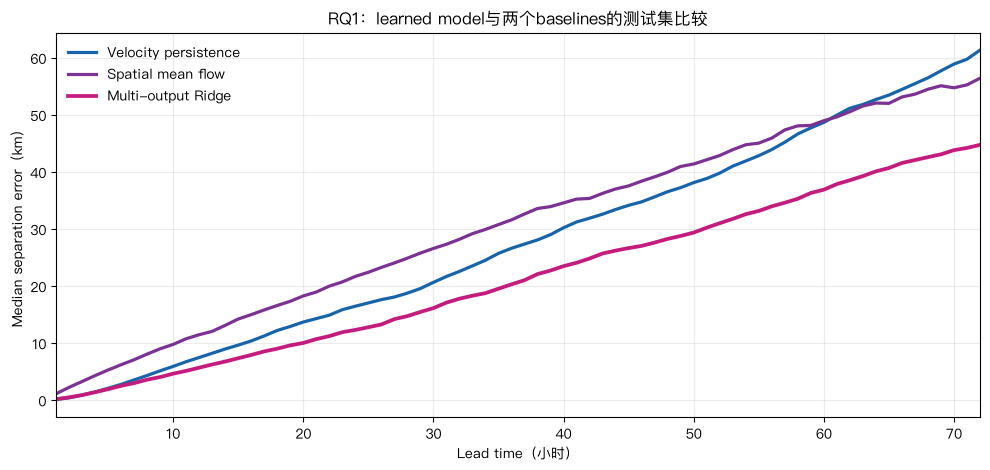

,ridge_median_km,persistence_median_km,mean_flow_median_km,ridge_rmse_km,persistence_rmse_km,mean_flow_rmse_km,ridge_rmse_minus_persistence_km,ridge_rmse_minus_mean_flow_km,skill_vs_persistence_pct,skill_vs_mean_flow_pct
lead_time_hours,,,,,,,,,,
24,12.32,16.47,21.69,18.97,24.07,29.87,-5.10,-10.89,21.17,36.47
48,28.27,36.54,39.96,42.59,55.17,57.27,-12.58,-14.68,22.81,25.64
72,44.75,61.35,56.42,65.91,90.10,80.98,-24.19,-15.07,26.85,18.60


In [10]:
persistence_metrics = pd.read_csv(OUTPUT_DIR / 'velocity_persistence_lead_metrics.csv')
mean_flow_metrics = pd.read_csv(OUTPUT_DIR / 'spatial_mean_flow_lead_metrics.csv')

comparison = (
    lead_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']]
    .rename(columns={
        'median_error_km': 'ridge_median_km',
        'rmse_km': 'ridge_rmse_km',
    })
    .merge(
        persistence_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': 'persistence_median_km',
            'rmse_km': 'persistence_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
    .merge(
        mean_flow_metrics[['lead_time_hours', 'median_error_km', 'rmse_km']].rename(columns={
            'median_error_km': 'mean_flow_median_km',
            'rmse_km': 'mean_flow_rmse_km',
        }), on='lead_time_hours', validate='one_to_one',
    )
)
comparison['ridge_rmse_minus_persistence_km'] = (
    comparison['ridge_rmse_km'] - comparison['persistence_rmse_km']
)
comparison['ridge_rmse_minus_mean_flow_km'] = (
    comparison['ridge_rmse_km'] - comparison['mean_flow_rmse_km']
)
comparison['skill_vs_persistence_pct'] = 100 * (
    1 - comparison['ridge_rmse_km'] / comparison['persistence_rmse_km']
)
comparison['skill_vs_mean_flow_pct'] = 100 * (
    1 - comparison['ridge_rmse_km'] / comparison['mean_flow_rmse_km']
)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(comparison['lead_time_hours'], comparison['persistence_median_km'],
        linewidth=2.3, color='#1764ab', label='Velocity persistence')
ax.plot(comparison['lead_time_hours'], comparison['mean_flow_median_km'],
        linewidth=2.3, color='#7b3294', label='Spatial mean flow')
ax.plot(comparison['lead_time_hours'], comparison['ridge_median_km'],
        linewidth=2.7, color='#c51b7d', label='Multi-output Ridge')
ax.set(
    xlabel='Lead time（小时）', ylabel='Median separation error（km）',
    title='RQ1：learned model与两个baselines的测试集比较',
)
ax.set_xlim(1, 72)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq1_three_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

comparison_table = comparison.loc[
    comparison['lead_time_hours'].isin([24, 48, 72]),
    [
        'lead_time_hours',
        'ridge_median_km', 'persistence_median_km', 'mean_flow_median_km',
        'ridge_rmse_km', 'persistence_rmse_km', 'mean_flow_rmse_km',
        'ridge_rmse_minus_persistence_km', 'ridge_rmse_minus_mean_flow_km',
        'skill_vs_persistence_pct', 'skill_vs_mean_flow_pct',
    ],
].set_index('lead_time_hours')
display(comparison_table.round(2))

## 10. Case-level integrated trajectory error与最终汇总

每个test case的ITE为0到72小时separation error曲线下方的梯形积分。最终同时报告24、48、72小时误差、72小时RMSE和Median ITE。

In [11]:
def case_metrics(group):
    ordered = group.sort_values('lead_time_hours')
    errors = ordered['separation_error_km'].to_numpy()
    hours = ordered['lead_time_hours'].to_numpy()
    ite = np.trapezoid(np.r_[0.0, errors], x=np.r_[0, hours])
    return pd.Series({
        'integrated_trajectory_error_km_h': ite,
        'final_72h_error_km': errors[-1],
        'mean_trajectory_error_km': errors.mean(),
    })

test_case_metrics = evaluation.groupby('forecast_case_id', sort=False).apply(
    case_metrics, include_groups=False
).reset_index()

def metric_at(hour, column):
    return float(lead_metrics.loc[lead_metrics['lead_time_hours'].eq(hour), column].iloc[0])

summary = pd.DataFrame({
    '指标': [
        'Selected alpha', 'Training cases', 'Calibration cases (unused)', 'Test cases',
        '24h median error (km)', '48h median error (km)', '72h median error (km)',
        '72h RMSE (km)', 'Median ITE (km·h)',
    ],
    '结果': [
        best_alpha, len(train_indices), len(calibration_indices), len(test_indices),
        metric_at(24, 'median_error_km'), metric_at(48, 'median_error_km'),
        metric_at(72, 'median_error_km'), metric_at(72, 'rmse_km'),
        test_case_metrics['integrated_trajectory_error_km_h'].median(),
    ],
})
display(summary.round(2))

,指标,结果
0,Selected alpha,100.00
1,Training cases,3591.00
2,Calibration cases (unused),769.00
3,Test cases,757.00
4,24h median error (km),12.32
5,48h median error (km),28.27
6,72h median error (km),44.75
7,72h RMSE (km),65.91
8,Median ITE (km·h),1531.79


## 11. 示例轨迹

选择Ridge模型72小时终点误差最接近测试集中位数的case，避免只展示最好或最差案例。

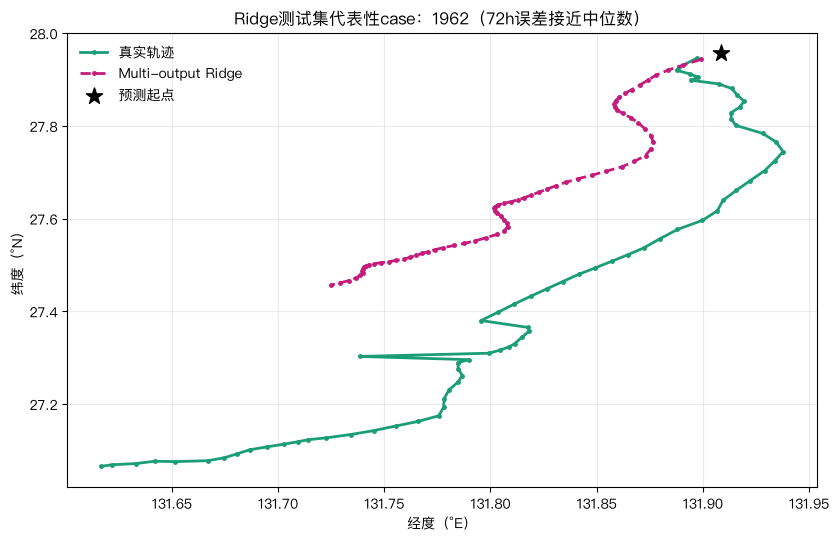

In [12]:
median_final = test_case_metrics['final_72h_error_km'].median()
example_id = test_case_metrics.loc[
    (test_case_metrics['final_72h_error_km'] - median_final).abs().idxmin(),
    'forecast_case_id',
]
example = evaluation[evaluation['forecast_case_id'].eq(example_id)].sort_values('lead_time_hours')

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(example['true_longitude'], example['true_latitude'], '-o', markersize=2.5,
        linewidth=2, color='#1b9e77', label='真实轨迹')
ax.plot(example['pred_longitude'], example['pred_latitude'], '--o', markersize=2.5,
        linewidth=2, color='#c51b7d', label='Multi-output Ridge')
ax.scatter(example['origin_longitude'].iloc[0], example['origin_latitude'].iloc[0],
           marker='*', s=150, color='black', label='预测起点', zorder=5)
ax.set(
    xlabel='经度（°E）', ylabel='纬度（°N）',
    title=f'Ridge测试集代表性case：{int(example_id)}（72h误差接近中位数）',
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'ridge_example_trajectory.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. 保存可复现结果

保存交叉验证、逐lead-time结果、case-level结果、三模型比较和poster可用图片。完整逐小时预测可以通过本notebook重建，因此不保存大型预测表。

In [13]:
cv_folds.to_csv(OUTPUT_DIR / 'ridge_cross_validation_folds.csv', index=False)
cv_results.to_csv(OUTPUT_DIR / 'ridge_cross_validation_summary.csv', index=False)
lead_metrics.to_csv(OUTPUT_DIR / 'ridge_lead_metrics.csv', index=False)
test_case_metrics.to_csv(OUTPUT_DIR / 'ridge_test_case_metrics.csv', index=False)
comparison.to_csv(OUTPUT_DIR / 'rq1_three_model_comparison.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'ridge_summary.csv', index=False)

np.savez_compressed(
    OUTPUT_DIR / 'ridge_model_parameters.npz',
    alpha=final_model['alpha'],
    x_mean=final_model['x_mean'],
    x_scale=final_model['x_scale'],
    y_mean=final_model['y_mean'],
    coefficients=final_model['coefficients'],
)

saved_files = sorted(
    [p.name for p in OUTPUT_DIR.glob('ridge_*')]
    + [p.name for p in OUTPUT_DIR.glob('rq1_three_model_*')]
)
print('已保存：')
for name in saved_files:
    print(' -', name)

已保存：
 - ridge_cross_validation.png
 - ridge_cross_validation_folds.csv
 - ridge_cross_validation_summary.csv
 - ridge_error_curve.png
 - ridge_example_trajectory.png
 - ridge_lead_metrics.csv
 - ridge_model_parameters.npz
 - ridge_summary.csv
 - ridge_test_case_metrics.csv
 - rq1_three_model_comparison.csv
 - rq1_three_model_comparison.png
